In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score, roc_curve

In [3]:
df = pd.read_csv('/content/student_pass_fail_dataset.csv')

print(df.head())
print(df.info())
print(df.isnull().sum())

   Study_Hours  Attendance  Pass_Fail
0            7          63          0
1            4          72          0
2            8          89          1
3            5          70          0
4            7          65          0
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 60 entries, 0 to 59
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   Study_Hours  60 non-null     int64
 1   Attendance   60 non-null     int64
 2   Pass_Fail    60 non-null     int64
dtypes: int64(3)
memory usage: 1.5 KB
None
Study_Hours    0
Attendance     0
Pass_Fail      0
dtype: int64


Pass_Fail
0    35
1    25
Name: count, dtype: int64


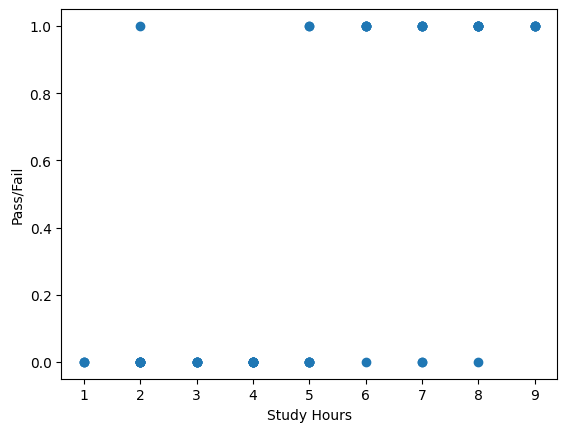

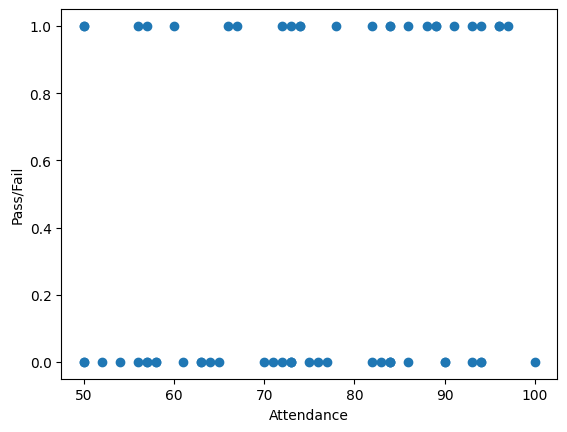

In [4]:
print(df['Pass_Fail'].value_counts())

plt.scatter(df['Study_Hours'], df['Pass_Fail'])
plt.xlabel('Study Hours')
plt.ylabel('Pass/Fail')
plt.show()

plt.scatter(df['Attendance'], df['Pass_Fail'])
plt.xlabel('Attendance')
plt.ylabel('Pass/Fail')
plt.show()

In [5]:
X = df[['Study_Hours', 'Attendance']]
y = df['Pass_Fail']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training data:", len(X_train))
print("Testing data:", len(X_test))

Training data: 48
Testing data: 12


In [6]:
model = LogisticRegression()
model.fit(X_train, y_train)

prob = model.predict_proba(X_test)[:, 1]
pred = (prob >= 0.5).astype(int)

print("Probabilities:", prob[:5])
print("Predictions:", pred[:5])

Probabilities: [0.1779982  0.97691936 0.99245449 0.0442257  0.95209913]
Predictions: [0 1 1 0 1]


In [7]:
for t in [0.3, 0.5, 0.7]:
    p = (prob >= t).astype(int)

    print("\nThreshold:", t)
    print("Accuracy:", accuracy_score(y_test, p))
    print("Precision:", precision_score(y_test, p, zero_division=0))
    print("Recall:", recall_score(y_test, p, zero_division=0))
    print("F1 Score:", f1_score(y_test, p, zero_division=0))


Threshold: 0.3
Accuracy: 0.9166666666666666
Precision: 0.8333333333333334
Recall: 1.0
F1 Score: 0.9090909090909091

Threshold: 0.5
Accuracy: 0.9166666666666666
Precision: 0.8333333333333334
Recall: 1.0
F1 Score: 0.9090909090909091

Threshold: 0.7
Accuracy: 0.9166666666666666
Precision: 0.8333333333333334
Recall: 1.0
F1 Score: 0.9090909090909091


In [8]:
cm = confusion_matrix(y_test, pred)

print("Confusion Matrix:\n", cm)
print("\nClassification Report:\n", classification_report(y_test, pred))

tn, fp, fn, tp = cm.ravel()
print("Specificity:", tn / (tn + fp))
print("ROC-AUC:", roc_auc_score(y_test, prob))

Confusion Matrix:
 [[6 1]
 [0 5]]

Classification Report:
               precision    recall  f1-score   support

           0       1.00      0.86      0.92         7
           1       0.83      1.00      0.91         5

    accuracy                           0.92        12
   macro avg       0.92      0.93      0.92        12
weighted avg       0.93      0.92      0.92        12

Specificity: 0.8571428571428571
ROC-AUC: 1.0


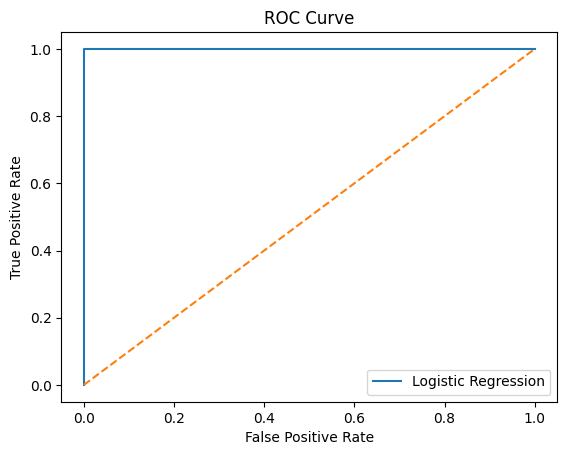

In [9]:
fpr, tpr, _ = roc_curve(y_test, prob)

plt.plot(fpr, tpr, label="Logistic Regression")
plt.plot([0, 1], [0, 1], '--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()

In [10]:
base = np.zeros(len(y_test))

print("Baseline Accuracy:", accuracy_score(y_test, base))
print("Model Accuracy:", accuracy_score(y_test, pred))

Baseline Accuracy: 0.5833333333333334
Model Accuracy: 0.9166666666666666


In [11]:
new = pd.DataFrame({
    'Study_Hours': [7],
    'Attendance': [85]
})

p = model.predict_proba(new)[0][1]

print("Pass Probability:", p)
print("Prediction:", "Pass" if p >= 0.5 else "Fail")

Pass Probability: 0.9418500852903221
Prediction: Pass
